In [116]:
import sys
import os

# Set this to the folder that CONTAINS the quantdata package folder
project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["MASSIVE_TOKEN"] = "jsnt7igBpyyAduX4WGdDEuw0gStWNVFk"
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date
from quantdata.massive.client import MassiveClient
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context


def test():

    ticker = "SPY"
    d = date(2024, 1, 3)
    client = MassiveClient()
    option_ticker = "O:SPY240105P00447000"

    def package(ticker, verbose=Context.all):

        with verbose.write_t(
            f"Fetching OCV, trades, quotes for {ticker} on {fmt_date(d)}... ", end=""
        ) as tme:
            ocv = client.fetch_day_summary(ticker, d, adjusted=True)
            verbose.write(f"done: found {fmt_dict(ocv)}. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching trades for {ticker} on {fmt_date(d)}... ", end="") as tme:
            trades = client.fetch_trades(ticker, d)
            verbose.write(f"done: found {len(trades)} trades. This took {tme}.", head=False)

        with verbose.write_t(f"Fetching quotes for {ticker} on {fmt_date(d)}... ", end="") as tme:
            quotes = client.fetch_quotes(ticker, d)
            verbose.write(f"done: found {len(quotes)} quotes. This took {tme}.", head=False)

        return ocv, trades, quotes

    package(ticker)
    ocv, trades, quotes = package(option_ticker)

    display(ocv)
    display(trades.head())
    display(quotes.head())


test()


00: Fetching OCV, trades, quotes for SPY on 2024-01-03... done: found open: 470.43, close: 468.79, volume: 103577866.0, high: 471.19, low: 468.17, afterHours: 469.35, preMarket: 472.07 and adjusted: True. This took 0.669ms.
00: Fetching trades for SPY on 2024-01-03... done: found 656589 trades. This took 7.92ms.
00: Fetching quotes for SPY on 2024-01-03... done: found 4927896 quotes. This took 0.021s.
00: Fetching OCV, trades, quotes for O:SPY240105P00447000 on 2024-01-03... done: found open: 0.03, close: 0.01, volume: 23.0, high: 0.03, low: 0.01, afterHours: 0.01, preMarket: 0.03 and adjusted: True. This took 0.612ms.
00: Fetching trades for O:SPY240105P00447000 on 2024-01-03... done: found 5 trades. This took 0.819ms.
00: Fetching quotes for O:SPY240105P00447000 on 2024-01-03... done: found 3561 quotes. This took 1.38ms.


/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


{'open': 0.03,
 'close': 0.01,
 'volume': 23.0,
 'high': 0.03,
 'low': 0.01,
 'afterHours': 0.01,
 'preMarket': 0.03,
 'adjusted': True}

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 10:22:10.541 EST,0.03,10.0,2624
2024-01-03 13:43:28.814 EST,0.02,2.0,2112
2024-01-03 14:42:27.471 EST,0.03,1.0,2112
2024-01-03 15:29:08.825 EST,0.02,5.0,64
2024-01-03 15:29:08.925 EST,0.01,5.0,576


ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.167173120 EST,0.01,20.0,0.04,219.0
2024-01-03 09:30:00.172450816 EST,0.02,202.0,0.03,202.0
2024-01-03 09:30:00.243299584 EST,0.02,1499.0,0.03,230.0
2024-01-03 09:30:00.438294016 EST,0.02,240.0,0.03,78.0
2024-01-03 09:30:00.522248704 EST,0.02,1260.0,0.03,249.0


In [3]:
client = MassiveClient()
df = client.fetch_trades("SPY", date(2024, 1, 3))

In [4]:
import polars as pl

df.head()

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728


In [5]:
df.shape

(656589, 4)

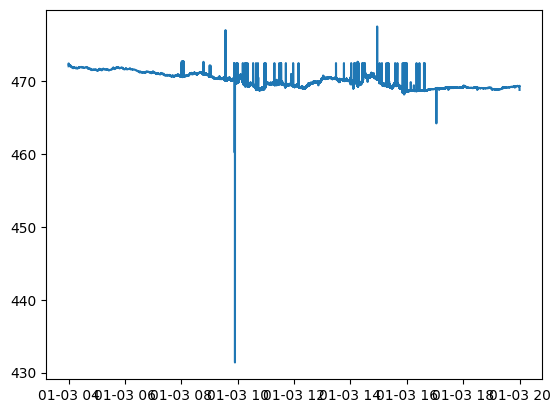

In [8]:
import matplotlib.pyplot as plt

pdf = df.to_pandas()
plt.plot(pdf["ts_ns"], pdf["price"])

In [10]:
type(df)

polars.dataframe.frame.DataFrame

In [11]:
df["trade_code"].unique()

trade_code
u32
0
256
8192
65536
73728
…
8585216
8650752
9437192


In [146]:
import os
import time
import csv
import requests
from datetime import datetime, timezone

API_KEY = "jsnt7igBpyyAduX4WGdDEuw0gStWNVFk"

UNDERLYING = "SPY"
OPTION_CONTRACT = "O:SPY240105P00447000"  # replace with your contract

URL = f"https://api.massive.com/v3/snapshot/options/{UNDERLYING}/{OPTION_CONTRACT}"

OUTFILE = "underlying_snapshots.csv"


def fetch_underlying_price():
    r = requests.get(URL, params={"apiKey": API_KEY}, timeout=10)
    r.raise_for_status()
    data = r.json()

    result = data.get("results", {})
    underlying = result.get("underlying_asset", {})

    return {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "underlying": UNDERLYING,
        "option_contract": OPTION_CONTRACT,
        "underlying_price": underlying.get("price"),
        "underlying_ticker": underlying.get("ticker"),
        "status": data.get("status"),
    }


def append_row(row):
    file_exists = os.path.exists(OUTFILE)

    with open(OUTFILE, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=row.keys())

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)


In [148]:
fetch_underlying_price()

HTTPError: 404 Client Error: Not Found for url: https://api.massive.com/v3/snapshot/options/SPY/O:SPY240105P00447000?apiKey=jsnt7igBpyyAduX4WGdDEuw0gStWNVFk

In [ ]:
while True:
    try:
        row = fetch_underlying_price()
        append_row(row)
        print(row)

    except Exception as e:
        print(f"{datetime.now(timezone.utc).isoformat()} ERROR: {e}")

    # time.sleep(60)

In [149]:
from massive import RESTClient

client = RESTClient(os.environ["MASSIVE_TOKEN"])

snapshot = client.get_snapshot_option("SPY", "O:SPY240105P00447000")

print(snapshot)


BadResponse: {"status":"ERROR","request_id":"51d92a42b58c2e0ca46b575682470387","error":"Options contract not found."}

In [150]:
import os
import requests
import pandas as pd

API_KEY = "jsnt7igBpyyAduX4WGdDEuw0gStWNVFk"


def fetch_spx_intraday(date: str, multiplier: int = 1, timespan: str = "minute") -> pd.DataFrame:
    """
    Fetch SPX index OHLC bars from Massive for one trading day.

    date: 'YYYY-MM-DD'
    multiplier: 1, 5, 15, etc.
    timespan: 'second', 'minute', 'hour', 'day'
    """
    ticker = "I:SPX"

    url = (
        f"https://api.massive.com/v2/aggs/ticker/{ticker}"
        f"/range/{multiplier}/{timespan}/{date}/{date}"
    )

    params = {
        "adjusted": "true",
        "sort": "asc",
        "limit": 50000,
        "apiKey": API_KEY,
    }

    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    data = r.json()

    rows = data.get("results", [])
    if not rows:
        return pd.DataFrame()

    df = pd.DataFrame(rows)

    # Massive aggregate timestamps are Unix ms.
    df["timestamp_utc"] = pd.to_datetime(df["t"], unit="ms", utc=True)
    df["timestamp_et"] = df["timestamp_utc"].dt.tz_convert("America/New_York")

    df = df.rename(
        columns={
            "o": "open",
            "h": "high",
            "l": "low",
            "c": "close",
            "v": "value_or_volume",
            "n": "num_updates",
        }
    )

    return df[
        [
            "timestamp_utc",
            "timestamp_et",
            "open",
            "high",
            "low",
            "close",
            "value_or_volume",
            "num_updates",
        ]
    ]


df = fetch_spx_intraday("2026-04-04", multiplier=1, timespan="minute")
print(df.head())
print(df.tail())

df.to_csv("spx_1min_2026-04-28.csv", index=False)

HTTPError: 403 Client Error: Forbidden for url: https://api.massive.com/v2/aggs/ticker/I:SPX/range/1/minute/2026-04-04/2026-04-04?adjusted=true&sort=asc&limit=50000&apiKey=jsnt7igBpyyAduX4WGdDEuw0gStWNVFk

In [136]:
import os
import requests
import pandas as pd

API_KEY = "77W2CKc7PLekAN7AypGKzdPh3jcWd5Ng"


def fetch_spx_1min(date: str) -> pd.DataFrame:
    ticker = "I:SPX"

    url = f"https://api.massive.com/v2/aggs/ticker/{ticker}/range/1/minute/{date}/{date}"

    params = {
        "adjusted": "true",
        "sort": "asc",
        "limit": 50000,
        "apiKey": API_KEY,
    }

    r = requests.get(url, params=params, timeout=30)
    print(r.url)
    r.raise_for_status()

    data = r.json()
    df = pd.DataFrame(data.get("results", []))

    if df.empty:
        return df

    df["timestamp_utc"] = pd.to_datetime(df["t"], unit="ms", utc=True)
    df["timestamp_et"] = df["timestamp_utc"].dt.tz_convert("America/New_York")

    df = df.rename(
        columns={
            "o": "open",
            "h": "high",
            "l": "low",
            "c": "close",
        }
    )

    df["spx_level"] = df["close"]

    return df[
        [
            "timestamp_utc",
            "timestamp_et",
            "open",
            "high",
            "low",
            "close",
            "spx_level",
        ]
    ]


df = fetch_spx_1min("2026-01-03")
print(df.head())
print(df.tail())

# df.to_csv("spx_1min_2025-01-03.csv", index=False)

https://api.massive.com/v2/aggs/ticker/I:SPX/range/1/minute/2026-01-03/2026-01-03?adjusted=true&sort=asc&limit=50000&apiKey=77W2CKc7PLekAN7AypGKzdPh3jcWd5Ng


HTTPError: 403 Client Error: Forbidden for url: https://api.massive.com/v2/aggs/ticker/I:SPX/range/1/minute/2026-01-03/2026-01-03?adjusted=true&sort=asc&limit=50000&apiKey=77W2CKc7PLekAN7AypGKzdPh3jcWd5Ng

In [133]:
from massive import RESTClient
import datetime

client = RESTClient("77W2CKc7PLekAN7AypGKzdPh3jcWd5Ng")

tickers = "I:SPX"
params = {"date": datetime.date(2025, 12, 12)}
snapshot = client.get_snapshot_indices(tickers, params=params)

# print raw values
print(snapshot)


BadResponse: {"status":"NOT_AUTHORIZED","request_id":"c612a36ac274588089dbc56ae06f021b","message":"You are not entitled to this data. Please upgrade your plan at https://massive.com/pricing"}

In [ ]:
# import plotly.express as px

# pdf = df.to_pandas()
# fig = px.line(pdf, x="ts_ns", y="price")
# fig.show()

In [12]:
from quantdata.massive.trade_conds import NORMAL_TRADE_EXCLUDE_FLAGS

In [15]:
int(NORMAL_TRADE_EXCLUDE_FLAGS)

16737343

In [17]:
df_good = df.filter((pl.col("trade_code") & int(NORMAL_TRADE_EXCLUDE_FLAGS)) == 0)

In [44]:
df_good.shape

(194450, 4)

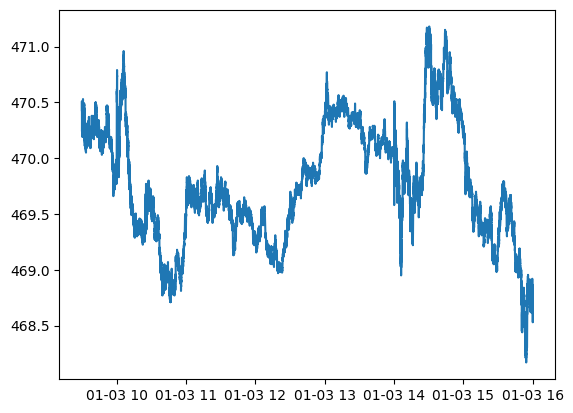

In [18]:
pdf_good = df_good.to_pandas()
plt.plot(pdf_good["ts_ns"], pdf_good["price"])

In [ ]:
import torch
from torch.func import jacrev


def ekf_step(x, P, z, f, h, Q, R):
    """
    x: [state_dim]
    P: [state_dim, state_dim]
    z: [obs_dim]
    f: function x -> x_next
    h: function x -> z_pred
    Q: process noise covariance
    R: measurement noise covariance
    """

    # Predict
    F = jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    # Update
    H = jacrev(h)(x_pred)
    y = z - h(x_pred)  # innovation
    S = H @ P_pred @ H.T + R  # innovation covariance

    # K = P_pred H.T S^{-1}, but avoid inverse
    K_T = torch.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y

    I = torch.eye(x.shape[0], device=x.device, dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred

    return x_new, P_new

In [20]:
import jax

In [21]:
import jax
import jax.numpy as jnp


def ekf_step(x, P, z, f, h, Q, R):
    """
    x: [state_dim]
    P: [state_dim, state_dim]
    z: [obs_dim]
    f: function x -> x_next
    h: function x -> z_pred
    Q: process noise covariance
    R: measurement noise covariance
    """

    # Predict
    F = jax.jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    # Update
    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R

    # K = P_pred H.T S^{-1}, but avoid inverse
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y

    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred

    return x_new, P_new

In [22]:
import jax
import jax.numpy as jnp


def ekf_step(x, P, z, f, h, Q, R):
    """
    Runs one Extended Kalman Filter step.

    x: current state estimate, shape [state_dim]
    P: current state covariance, shape [state_dim, state_dim]
    z: new measurement, shape [obs_dim]
    f: motion / dynamics function, maps state -> predicted next state
    h: measurement function, maps state -> predicted measurement
    Q: process noise covariance
    R: measurement noise covariance
    """

    # 1. Linearize the nonlinear motion model f around the current state.
    # F is the Jacobian of f, used to approximate how uncertainty moves forward.
    F = jax.jacrev(f)(x)

    # 2. Predict the next state using the motion model.
    x_pred = f(x)

    # 3. Predict the next covariance.
    # This says how uncertain we are after applying the motion model,
    # plus extra uncertainty from process noise Q.
    P_pred = F @ P @ F.T + Q

    # 4. Linearize the nonlinear measurement model h around the predicted state.
    # H maps state uncertainty into measurement uncertainty.
    H = jax.jacrev(h)(x_pred)

    # 5. Compute the innovation / residual.
    # This is the difference between the real measurement and predicted measurement.
    y = z - h(x_pred)

    # 6. Compute the innovation covariance.
    # S describes how uncertain the innovation is.
    S = H @ P_pred @ H.T + R

    # 7. Compute the Kalman gain.
    # The gain decides how much we trust the measurement versus the prediction.
    # solve(...) is used instead of explicitly computing inverse(S).
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    # 8. Update the state estimate using the innovation weighted by Kalman gain.
    x_new = x_pred + K @ y

    # 9. Update the covariance.
    # After using the measurement, uncertainty should usually decrease.
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred

    return x_new, P_new

In [23]:
def f(x):
    # Assume tomorrow's true price is close to today's true price
    return x


def h(x):
    # Observed price is a noisy version of the true price
    return x

In [26]:
def estimate_true_price_polars(df_good: pl.DataFrame) -> pl.DataFrame:
    # Convert column to JAX array
    prices = jnp.array(df_good["price"].to_numpy(), dtype=jnp.float32)

    # Initial state (first observed price)
    x = jnp.array([prices[0]])

    # Initial covariance
    P = jnp.array([[1.0]])

    # Tune these depending on how smooth vs reactive you want it
    Q = jnp.array([[0.05]])  # process noise
    R = jnp.array([[1.0]])  # measurement noise

    estimates = []

    for price in prices:
        z = jnp.array([price])

        x, P = ekf_step(x, P, z, f, h, Q, R)

        estimates.append(float(x[0]))

    # Add result back to Polars DataFrame
    return df_good.with_columns(pl.Series(name="estimated_true_price", values=estimates))

In [35]:
N = 10000

In [36]:
df_result = estimate_true_price_polars(df_good.select("price").head(N))

In [37]:
df_result

price,estimated_true_price
f64,f64
470.43,470.429993
470.46,470.440796
470.46,470.446381
470.4301,470.442261
470.46,470.446381
…,…
470.21,470.202515
470.21,470.20401
470.22,470.207214


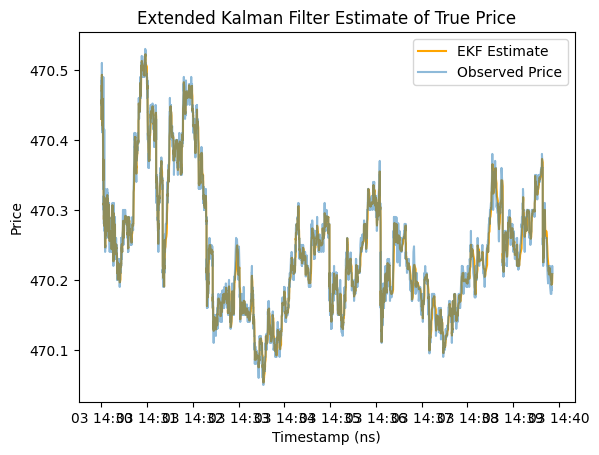

In [38]:
plt.plot(
    df_good.select("ts_ns").head(N),
    df_result["estimated_true_price"],
    label="EKF Estimate",
    color="orange",
)
plt.plot(df_good.select("ts_ns").head(N), df_result["price"], label="Observed Price", alpha=0.5)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

In [39]:
import jax

print(jax.devices())
print(jax.default_backend())

[CpuDevice(id=0)]
cpu


In [41]:
import jax
import jax.numpy as jnp
import polars as pl

Q = 0.05  # higher = reacts faster
R = 1.0  # higher = smoother


# State: x = [true_price]
def f(x):
    # Prediction model: true price stays close to previous true price
    return x


def h(x):
    # Measurement model: observed price is noisy true price
    return x


def ekf_step(x, P, z, Q, R):
    # Predict state
    F = jax.jacrev(f)(x)
    x_pred = f(x)

    # Predict uncertainty
    P_pred = F @ P @ F.T + Q

    # Measurement update
    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R

    # Kalman gain
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    # Correct state estimate
    x_new = x_pred + K @ y

    # Correct uncertainty
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred

    return x_new, P_new


@jax.jit
def run_ekf(prices):
    x0 = jnp.array([prices[0]], dtype=jnp.float32)
    P0 = jnp.array([[1.0]], dtype=jnp.float32)

    Q = jnp.array([[0.05]], dtype=jnp.float32)
    R = jnp.array([[1.0]], dtype=jnp.float32)

    def scan_step(carry, price):
        x, P = carry
        z = jnp.array([price], dtype=jnp.float32)

        x_new, P_new = ekf_step(x, P, z, Q, R)

        return (x_new, P_new), x_new[0]

    (_, _), estimates = jax.lax.scan(scan_step, (x0, P0), prices)

    return estimates


def estimate_true_price(df_good: pl.DataFrame) -> pl.DataFrame:
    prices = jnp.array(df_good["price"].to_numpy(), dtype=jnp.float32)

    estimates = run_ekf(prices)

    return df_good.with_columns(
        pl.Series(name="estimated_true_price", values=jax.device_get(estimates).tolist())
    )


# Usage
df_result = estimate_true_price(df_good)

In [42]:
df_result

ts_ns,price,size,trade_code,estimated_true_price
"datetime[ns, America/New_York]",f64,f64,u32,f64
2024-01-03 09:30:00.003119872 EST,470.43,100.0,0,470.429993
2024-01-03 09:30:00.021508608 EST,470.46,100.0,0,470.440796
2024-01-03 09:30:00.021577984 EST,470.46,100.0,0,470.446381
2024-01-03 09:30:00.033044224 EST,470.4301,741.0,0,470.442261
2024-01-03 09:30:00.035522560 EST,470.46,100.0,0,470.446381
…,…,…,…,…
2024-01-03 16:00:00.050740480 EST,468.74,300.0,0,468.731628
2024-01-03 16:00:00.050803456 EST,468.74,400.0,0,468.733307
2024-01-03 16:00:00.050809600 EST,468.74,100.0,0,468.73465


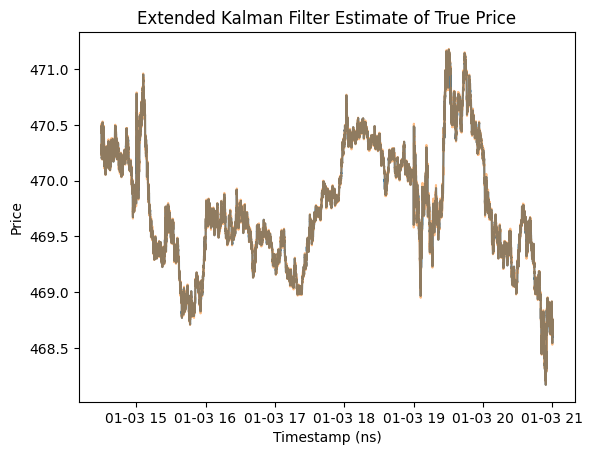

In [43]:
plt.plot(df_result["ts_ns"], df_result["estimated_true_price"])
plt.plot(df_result["ts_ns"], df_result["price"], alpha=0.5)
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

In [45]:
# compile + run
_ = estimate_true_price(df_good)

# benchmark actual cached execution
%timeit estimate_true_price(df_good)

111 ms ± 2.84 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


## First look at quotes

In [46]:
df_quotes = client.fetch_quotes("SPY", date(2024, 1, 3))

In [47]:
df_quotes.describe()

statistic,ts_ns,bid_price,bid_size,ask_price,ask_size
str,str,f64,f64,f64,f64
"""count""","""4927896""",4.927896e6,4.927896e6,4.927896e6,4.927896e6
"""null_count""","""0""",0.0,0.0,0.0,0.0
"""mean""","""2024-01-03 12:43:23.942041-05:…",469.772879,727.385318,469.782761,664.453024
"""std""",null,0.673816,671.78699,0.707076,1005.885599
"""min""","""2024-01-03 03:59:00.022993-05:…",0.0,0.0,0.0,0.0
"""25%""","""2024-01-03 10:43:01.550328-05:…",469.39,300.0,469.4,300.0
"""50%""","""2024-01-03 12:50:21.241291-05:…",469.69,500.0,469.7,500.0
"""75%""","""2024-01-03 14:32:28.709748-05:…",470.22,900.0,470.23,800.0
"""max""","""2024-01-03 20:00:00.323694-05:…",472.2,23800.0,472.24,169000.0


In [48]:
df_quotes

ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 03:59:00.022993920 EST,0.0,0.0,0.0,0.0
2024-01-03 03:59:00.089637376 EST,0.0,0.0,0.0,0.0
2024-01-03 04:00:00.000916992 EST,471.91,500.0,0.0,0.0
2024-01-03 04:00:00.001017088 EST,471.91,500.0,472.13,500.0
2024-01-03 04:00:00.009457152 EST,471.91,600.0,472.13,500.0
…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,469.35,100.0,469.36,1900.0
2024-01-03 20:00:00.000471808 EST,469.35,100.0,469.36,1100.0
2024-01-03 20:00:00.004842240 EST,469.35,100.0,469.36,900.0


In [49]:
df_quotes.select("ts_ns").unique().shape

(4578851, 1)

In [50]:
df_good

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 09:30:00.003119872 EST,470.43,100.0,0
2024-01-03 09:30:00.021508608 EST,470.46,100.0,0
2024-01-03 09:30:00.021577984 EST,470.46,100.0,0
2024-01-03 09:30:00.033044224 EST,470.4301,741.0,0
2024-01-03 09:30:00.035522560 EST,470.46,100.0,0
…,…,…,…
2024-01-03 16:00:00.050740480 EST,468.74,300.0,0
2024-01-03 16:00:00.050803456 EST,468.74,400.0,0
2024-01-03 16:00:00.050809600 EST,468.74,100.0,0


# Merging

In [ ]:
quotes_for_join = df_quotes.rename({"ts_ns": "quote_ts_ns"})

df_trade_spread = df_good.join_asof(
    quotes_for_join.sort("quote_ts_ns"),
    left_on="ts_ns",
    right_on="quote_ts_ns",
    strategy="backward",
)

df_trade_spread = df_trade_spread.with_columns(
    (pl.col("ts_ns") - pl.col("quote_ts_ns")).alias("quote_age")
)

In [ ]:
df_trade_spread

ts_ns,price,size,trade_code,quote_ts_ns,bid_price,bid_size,ask_price,ask_size,quote_age
"datetime[ns, America/New_York]",f64,f64,u32,"datetime[ns, America/New_York]",f64,f64,f64,f64,duration[ns]
2024-01-03 09:30:00.003119872 EST,470.43,100.0,0,2024-01-03 09:30:00.002855936 EST,470.43,100.0,470.44,900.0,263936ns
2024-01-03 09:30:00.021508608 EST,470.46,100.0,0,2024-01-03 09:30:00.010223616 EST,470.46,1700.0,470.47,100.0,11284992ns
2024-01-03 09:30:00.021577984 EST,470.46,100.0,0,2024-01-03 09:30:00.010223616 EST,470.46,1700.0,470.47,100.0,11354368ns
2024-01-03 09:30:00.033044224 EST,470.4301,741.0,0,2024-01-03 09:30:00.032340992 EST,470.46,1400.0,470.47,100.0,703232ns
2024-01-03 09:30:00.035522560 EST,470.46,100.0,0,2024-01-03 09:30:00.035087616 EST,470.46,3400.0,470.47,100.0,434944ns
…,…,…,…,…,…,…,…,…,…
2024-01-03 16:00:00.050740480 EST,468.74,300.0,0,2024-01-03 16:00:00.050669824 EST,468.73,7300.0,468.74,169000.0,70656ns
2024-01-03 16:00:00.050803456 EST,468.74,400.0,0,2024-01-03 16:00:00.050760192 EST,468.73,8400.0,468.74,169000.0,43264ns
2024-01-03 16:00:00.050809600 EST,468.74,100.0,0,2024-01-03 16:00:00.050760192 EST,468.73,8400.0,468.74,169000.0,49408ns


In [ ]:
(df_trade_spread.select("bid_size") == 0).sum()

bid_size
u32
0


In [58]:
import polars as pl

quote_events = df_quotes.with_columns(
    [
        pl.lit("quote").alias("event_type"),
        (
            (pl.col("ask_size") * pl.col("bid_price") + pl.col("bid_size") * pl.col("ask_price"))
            / (pl.col("bid_size") + pl.col("ask_size"))
        ).alias("observed_price"),
        (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
    ]
)

trade_events = df_good.join_asof(
    df_quotes.rename({"ts_ns": "quote_ts_ns"}).sort("quote_ts_ns"),
    left_on="ts_ns",
    right_on="quote_ts_ns",
    strategy="backward",
).with_columns(
    [
        pl.lit("trade").alias("event_type"),
        pl.col("price").alias("observed_price"),
        (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
    ]
)

In [59]:
events = pl.concat(
    [
        quote_events.select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
            ]
        ),
        trade_events.select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
            ]
        ),
    ]
).sort("ts_ns")

In [60]:
events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64
2024-01-03 03:59:00.022993920 EST,"""quote""",NaN,0.0,0.0,0.0,0.0,0.0
2024-01-03 03:59:00.089637376 EST,"""quote""",NaN,0.0,0.0,0.0,0.0,0.0
2024-01-03 04:00:00.000916992 EST,"""quote""",0.0,-471.91,471.91,0.0,500.0,0.0
2024-01-03 04:00:00.001017088 EST,"""quote""",472.02,0.22,471.91,472.13,500.0,500.0
2024-01-03 04:00:00.009457152 EST,"""quote""",472.03,0.22,471.91,472.13,600.0,500.0
…,…,…,…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,"""quote""",469.3505,0.01,469.35,469.36,100.0,1900.0
2024-01-03 20:00:00.000471808 EST,"""quote""",469.350833,0.01,469.35,469.36,100.0,1100.0
2024-01-03 20:00:00.004842240 EST,"""quote""",469.351,0.01,469.35,469.36,100.0,900.0


In [73]:
events.select(pl.col("observed_price").is_nan().sum())

observed_price
u32
2


In [74]:
events = events.drop_nans()

In [75]:
events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64
2024-01-03 04:00:00.000916992 EST,"""quote""",0.0,-471.91,471.91,0.0,500.0,0.0
2024-01-03 04:00:00.001017088 EST,"""quote""",472.02,0.22,471.91,472.13,500.0,500.0
2024-01-03 04:00:00.009457152 EST,"""quote""",472.03,0.22,471.91,472.13,600.0,500.0
2024-01-03 04:00:00.023671040 EST,"""quote""",472.082174,0.22,471.91,472.13,1800.0,500.0
2024-01-03 04:00:00.023676160 EST,"""quote""",472.08,0.1,472.03,472.13,500.0,500.0
…,…,…,…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,"""quote""",469.3505,0.01,469.35,469.36,100.0,1900.0
2024-01-03 20:00:00.000471808 EST,"""quote""",469.350833,0.01,469.35,469.36,100.0,1100.0
2024-01-03 20:00:00.004842240 EST,"""quote""",469.351,0.01,469.35,469.36,100.0,900.0


In [76]:
df_quotes

ts_ns,bid_price,bid_size,ask_price,ask_size
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 03:59:00.022993920 EST,0.0,0.0,0.0,0.0
2024-01-03 03:59:00.089637376 EST,0.0,0.0,0.0,0.0
2024-01-03 04:00:00.000916992 EST,471.91,500.0,0.0,0.0
2024-01-03 04:00:00.001017088 EST,471.91,500.0,472.13,500.0
2024-01-03 04:00:00.009457152 EST,471.91,600.0,472.13,500.0
…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,469.35,100.0,469.36,1900.0
2024-01-03 20:00:00.000471808 EST,469.35,100.0,469.36,1100.0
2024-01-03 20:00:00.004842240 EST,469.35,100.0,469.36,900.0


In [82]:
import polars as pl
import numpy as np

# ── CONFIG ──────────────────────────────────────────────────────────────────
ONE_SIDED_R_MULTIPLIER = 10.0  # inflate variance for one-sided quotes
TRADE_R_DIVISOR = 4.0  # trades are more trusted than quotes
STALE_QUOTE_THRESHOLD = 60_000  # ms — mark quote as stale beyond this


# ── 1. PROCESS QUOTES ───────────────────────────────────────────────────────
def process_quotes(df_quotes: pl.DataFrame) -> pl.DataFrame:
    """
    Input columns expected: ts_ns, bid, ask, bid_size, ask_size
    Zeros are treated as missing.
    """
    df = (
        df_quotes.with_columns(
            [
                # treat 0 as null
                pl.when(pl.col("bid_price") <= 0)
                .then(None)
                .otherwise(pl.col("bid_price"))
                .alias("bid_price"),
                pl.when(pl.col("ask_price") <= 0)
                .then(None)
                .otherwise(pl.col("ask_price"))
                .alias("ask_price"),
                pl.when(pl.col("bid_size") <= 0)
                .then(None)
                .otherwise(pl.col("bid_size"))
                .alias("bid_size"),
                pl.when(pl.col("ask_size") <= 0)
                .then(None)
                .otherwise(pl.col("ask_size"))
                .alias("ask_size"),
            ]
        )
        .with_columns(
            [
                # classify quote side
                pl.when(pl.col("bid_price").is_not_null() & pl.col("ask_price").is_not_null())
                .then(pl.lit("two_sided"))
                .when(pl.col("bid_price").is_not_null())
                .then(pl.lit("bid_only"))
                .when(pl.col("ask_price").is_not_null())
                .then(pl.lit("ask_only"))
                .otherwise(pl.lit("empty"))
                .alias("quote_side"),
            ]
        )
        # drop rows where both sides are missing
        .filter(pl.col("quote_side") != "empty")
        .with_columns(
            [
                # ── observed price (microprice, or fallback) ──────────────────
                pl.when(pl.col("quote_side") == "two_sided")
                .then(
                    (
                        pl.col("ask_size") * pl.col("bid_price")
                        + pl.col("bid_size") * pl.col("ask_price")
                    )
                    / (pl.col("ask_size") + pl.col("bid_size"))
                )
                .when(pl.col("quote_side") == "bid_only")
                .then(pl.col("bid_price"))
                .otherwise(pl.col("ask_price"))
                .alias("observed_price"),
                # ── spread ────────────────────────────────────────────────────
                pl.when(pl.col("quote_side") == "two_sided")
                .then(pl.col("ask_price") - pl.col("bid_price"))
                .otherwise(None)
                .alias("spread"),
            ]
        )
        .with_columns(
            [
                pl.col("spread").fill_null(strategy="forward").alias("spread_filled"),
            ]
        )
        .with_columns(
            [
                # ── variance R ────────────────────────────────────────────────
                pl.when(pl.col("quote_side") == "two_sided")
                .then(
                    (pl.col("spread") / 2) ** 2
                    / (1 + (pl.col("bid_size") + pl.col("ask_size")).log1p())
                )
                .otherwise((pl.col("spread_filled") / 2) ** 2 * ONE_SIDED_R_MULTIPLIER)
                .alias("R"),
                pl.lit("quote").alias("event_type"),
            ]
        )
        .select(
            [
                "ts_ns",
                "event_type",
                "observed_price",
                "spread",
                "bid_price",
                "ask_price",
                "bid_size",
                "ask_size",
                "R",
            ]
        )
    )
    return df


# ── 2. PROCESS TRADES ───────────────────────────────────────────────────────
def process_trades(df_trades: pl.DataFrame, df_quotes_processed: pl.DataFrame) -> pl.DataFrame:
    """
    Input columns expected: ts_ns, price
    Attaches market context from the latest preceding quote via asof join.
    """
    # asof join: for each trade, get the latest quote at or before its ts_ns
    df_context = (
        df_quotes_processed.sort("ts_ns")
        .select(["ts_ns", "spread", "bid_price", "ask_price"])
        .rename({"ts_ns": "quote_ts_ns"})
    )

    df = (
        df_trades.sort("ts_ns")
        .join_asof(
            df_context.rename({"quote_ts_ns": "ts_ns"}),
            on="ts_ns",
            strategy="backward",
        )
        .with_columns(
            [
                # ── quote age ─────────────────────────────────────────────────
                # (requires quote_ts_ns to be carried — add it to context if needed)
                pl.lit("trade").alias("event_type"),
                pl.col("price").alias("observed_price"),
            ]
        )
        .with_columns(
            [
                # ── variance R (lower than quotes, but inflates if spread is wide) ──
                pl.when(pl.col("spread").is_not_null())
                .then((pl.col("spread") / 2) ** 2 / TRADE_R_DIVISOR)
                .otherwise(
                    (pl.col("observed_price") * 0.01) ** 2  # fallback if no quote context
                )
                .alias("R"),
            ]
        )
        .select(["ts_ns", "event_type", "observed_price", "spread", "bid_price", "ask_price", "R"])
    )
    return df


# ── 3. MERGE INTO EVENT STREAM ───────────────────────────────────────────────
def build_event_stream(df_quotes: pl.DataFrame, df_trades: pl.DataFrame) -> pl.DataFrame:
    df_q = process_quotes(df_quotes)
    df_t = process_trades(df_trades, df_q)

    df_events = (
        pl.concat([df_q, df_t], how="diagonal")
        .sort("ts_ns")
        .with_columns(pl.col("spread").fill_null(strategy="forward"))  # carry last spread forward
    )
    return df_events


# ── 4. KALMAN FILTER ─────────────────────────────────────────────────────────
def kalman_filter(df_events: pl.DataFrame, Q: float = 0.01) -> pl.DataFrame:
    """
    Simple 1D random-walk Kalman filter.
    Q = process noise variance (how fast true price can move)
    """
    obs_prices = df_events["observed_price"].to_numpy()
    Rs = df_events["R"].to_numpy()
    n = len(obs_prices)

    x_est = np.empty(n)  # filtered state (true price estimate)
    P_est = np.empty(n)  # filtered uncertainty

    # initialise with first observation
    x_est[0] = obs_prices[0]
    P_est[0] = Rs[0]

    for t in range(1, n):
        # ── predict ──────────────────────────────────────────────────────
        x_pred = x_est[t - 1]
        P_pred = P_est[t - 1] + Q

        # ── update ───────────────────────────────────────────────────────
        R_t = Rs[t]
        K = P_pred / (P_pred + R_t)  # Kalman gain

        x_est[t] = x_pred + K * (obs_prices[t] - x_pred)
        P_est[t] = (1 - K) * P_pred

    return df_events.with_columns(
        [
            pl.Series("kalman_price", x_est),
            pl.Series("kalman_var", P_est),
        ]
    )


# ── USAGE ────────────────────────────────────────────────────────────────────
# df_events  = build_event_stream(df_quotes, df_trades)
# df_results = kalman_filter(df_events, Q=0.01)

In [101]:
df_events = build_event_stream(df_quotes, df_good)

In [102]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64
2024-01-03 04:00:00.000916992 EST,"""quote""",471.91,null,471.91,null,500.0,null,null
2024-01-03 04:00:00.001017088 EST,"""quote""",472.02,0.22,471.91,472.13,500.0,500.0,0.00153
2024-01-03 04:00:00.009457152 EST,"""quote""",472.03,0.22,471.91,472.13,600.0,500.0,0.001512
2024-01-03 04:00:00.023671040 EST,"""quote""",472.082174,0.22,471.91,472.13,1800.0,500.0,0.001384
2024-01-03 04:00:00.023676160 EST,"""quote""",472.08,0.1,472.03,472.13,500.0,500.0,0.000316
…,…,…,…,…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,"""quote""",469.3505,0.01,469.35,469.36,100.0,1900.0,0.000003
2024-01-03 20:00:00.000471808 EST,"""quote""",469.350833,0.01,469.35,469.36,100.0,1100.0,0.000003
2024-01-03 20:00:00.004842240 EST,"""quote""",469.351,0.01,469.35,469.36,100.0,900.0,0.000003


In [103]:
df_events.select(pl.col("R").is_null().sum())

R
u32
1


In [105]:
df_events = df_events.filter(pl.col("R").is_not_null())

In [106]:
df_events

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64
2024-01-03 04:00:00.001017088 EST,"""quote""",472.02,0.22,471.91,472.13,500.0,500.0,0.00153
2024-01-03 04:00:00.009457152 EST,"""quote""",472.03,0.22,471.91,472.13,600.0,500.0,0.001512
2024-01-03 04:00:00.023671040 EST,"""quote""",472.082174,0.22,471.91,472.13,1800.0,500.0,0.001384
2024-01-03 04:00:00.023676160 EST,"""quote""",472.08,0.1,472.03,472.13,500.0,500.0,0.000316
2024-01-03 04:00:00.023726080 EST,"""quote""",472.085556,0.08,472.05,472.13,400.0,500.0,0.000205
…,…,…,…,…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,"""quote""",469.3505,0.01,469.35,469.36,100.0,1900.0,0.000003
2024-01-03 20:00:00.000471808 EST,"""quote""",469.350833,0.01,469.35,469.36,100.0,1100.0,0.000003
2024-01-03 20:00:00.004842240 EST,"""quote""",469.351,0.01,469.35,469.36,100.0,900.0,0.000003


In [107]:
import jax
import jax.numpy as jnp
import polars as pl


def f(x):
    return x


def h(x):
    return x


def ekf_step(x, P, z, R_scalar, Q):
    F = jax.jacrev(f)(x)
    x_pred = f(x)
    P_pred = F @ P @ F.T + Q

    H = jax.jacrev(h)(x_pred)
    y = z - h(x_pred)
    S = H @ P_pred @ H.T + R_scalar
    K_T = jnp.linalg.solve(S, H @ P_pred)
    K = K_T.T

    x_new = x_pred + K @ y
    I = jnp.eye(x.shape[0], dtype=x.dtype)
    P_new = (I - K @ H) @ P_pred
    return x_new, P_new


@jax.jit
def run_ekf(prices, Rs):
    x0 = jnp.array([prices[0]], dtype=jnp.float32)
    P0 = jnp.array([[1.0]], dtype=jnp.float32)
    Q = jnp.array([[0.05]], dtype=jnp.float32)

    def scan_step(carry, obs):
        x, P = carry
        price, R_scalar = obs
        z = jnp.array([price], dtype=jnp.float32)
        R = jnp.array([[R_scalar]], dtype=jnp.float32)
        x_new, P_new = ekf_step(x, P, z, R, Q)
        return (x_new, P_new), x_new[0]

    (_, _), estimates = jax.lax.scan(scan_step, (x0, P0), (prices, Rs))
    return estimates


def estimate_true_price(df_events: pl.DataFrame) -> pl.DataFrame:
    prices = jnp.array(df_events["observed_price"].to_numpy(), dtype=jnp.float32)
    Rs = jnp.array(df_events["R"].to_numpy(), dtype=jnp.float32)

    estimates = run_ekf(prices, Rs)

    return df_events.with_columns(
        pl.Series(name="kalman_price", values=jax.device_get(estimates).tolist())
    )


# Usage
df_result = estimate_true_price(df_events)

In [108]:
df_result

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,kalman_price
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 04:00:00.001017088 EST,"""quote""",472.02,0.22,471.91,472.13,500.0,500.0,0.00153,472.019989
2024-01-03 04:00:00.009457152 EST,"""quote""",472.03,0.22,471.91,472.13,600.0,500.0,0.001512,472.029724
2024-01-03 04:00:00.023671040 EST,"""quote""",472.082174,0.22,471.91,472.13,1800.0,500.0,0.001384,472.080811
2024-01-03 04:00:00.023676160 EST,"""quote""",472.08,0.1,472.03,472.13,500.0,500.0,0.000316,472.079987
2024-01-03 04:00:00.023726080 EST,"""quote""",472.085556,0.08,472.05,472.13,400.0,500.0,0.000205,472.08551
…,…,…,…,…,…,…,…,…,…
2024-01-03 19:59:59.001761792 EST,"""quote""",469.3505,0.01,469.35,469.36,100.0,1900.0,0.000003,469.350494
2024-01-03 20:00:00.000471808 EST,"""quote""",469.350833,0.01,469.35,469.36,100.0,1100.0,0.000003,469.35083
2024-01-03 20:00:00.004842240 EST,"""quote""",469.351,0.01,469.35,469.36,100.0,900.0,0.000003,469.351013


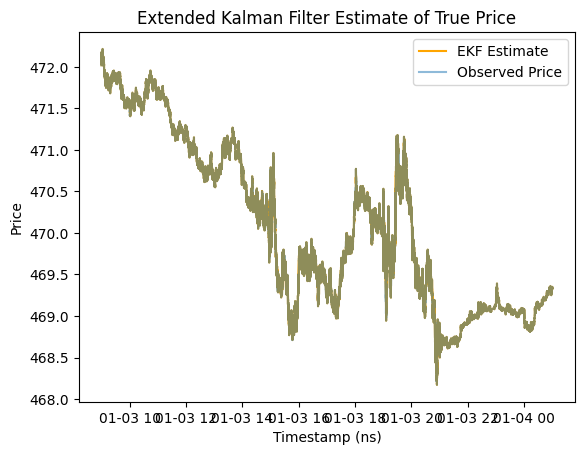

In [109]:
plt.plot(df_result["ts_ns"], df_result["kalman_price"], label="EKF Estimate", color="orange")
plt.plot(df_result["ts_ns"], df_result["observed_price"], label="Observed Price", alpha=0.5)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

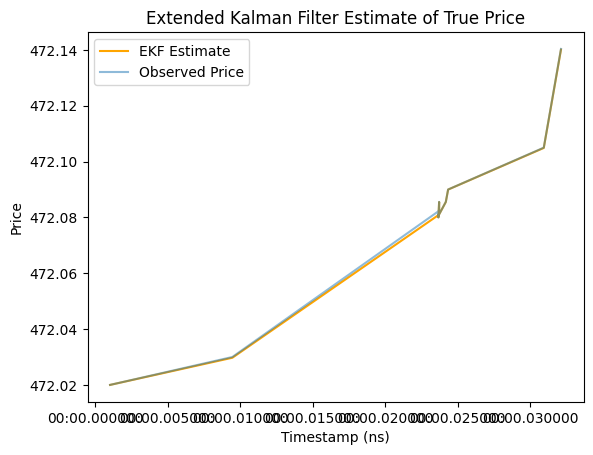

In [112]:
N = 10

plt.plot(
    df_result["ts_ns"].head(N),
    df_result["kalman_price"].head(N),
    label="EKF Estimate",
    color="orange",
)
plt.plot(
    df_result["ts_ns"].head(N),
    df_result["observed_price"].head(N),
    label="Observed Price",
    alpha=0.5,
)
plt.legend()
plt.title("Extended Kalman Filter Estimate of True Price")
plt.xlabel("Timestamp (ns)")
plt.ylabel("Price")
plt.show()

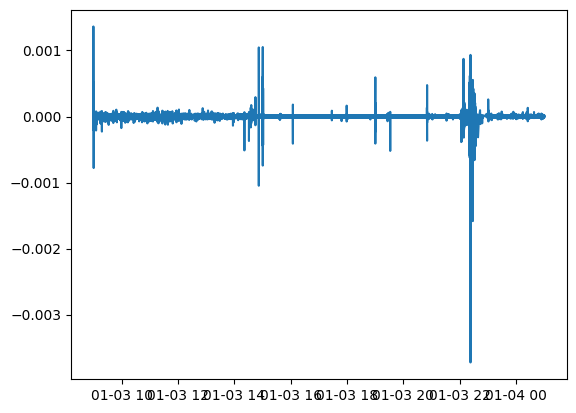

In [114]:
plt.plot(df_result["ts_ns"], df_result["observed_price"] - df_result["kalman_price"])

In [ ]:
import jax.numpy as jnp
from jax.scipy.special import ndtr  # fast normal CDF


def bs_call_price(S, K, T, r, sigma):
    sqrtT = jnp.sqrt(T)
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    d2 = d1 - sigma * sqrtT
    return S * ndtr(d1) - K * jnp.exp(-r * T) * ndtr(d2)


def bs_vega(S, K, T, r, sigma):
    sqrtT = jnp.sqrt(T)
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    pdf = jnp.exp(-0.5 * d1**2) / jnp.sqrt(2 * jnp.pi)
    return S * sqrtT * pdf


@jax.jit
def implied_vol_batch(price, S, K, T, r, n_iter=20):
    sigma = jnp.full_like(price, 0.2)

    def step(_, sigma):
        model = bs_call_price(S, K, T, r, sigma)
        vega = bs_vega(S, K, T, r, sigma)
        sigma = sigma - (model - price) / jnp.maximum(vega, 1e-8)
        return jnp.clip(sigma, 1e-4, 5.0)

    sigma = jax.lax.fori_loop(0, n_iter, step, sigma)
    return sigma

In [ ]:
import jax
import jax.numpy as jnp
import polars as pl
from functools import partial


# --- Black-Scholes price & vega ---
@jax.jit
def bs_call_price(S, K, T, r, sigma):
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * jnp.sqrt(T))
    d2 = d1 - sigma * jnp.sqrt(T)
    norm = jax.scipy.stats.norm
    return S * norm.cdf(d1) - K * jnp.exp(-r * T) * norm.cdf(d2)


@jax.jit
def bs_vega(S, K, T, r, sigma):
    d1 = (jnp.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * jnp.sqrt(T))
    return S * jax.scipy.stats.norm.pdf(d1) * jnp.sqrt(T)


# --- Single Newton-Raphson step ---
@jax.jit
def newton_iv(market_price, S, K, T, r, max_iter=10):
    sigma = jnp.full_like(market_price, 0.3)  # initial guess

    def step(sigma, _):
        price = bs_call_price(S, K, T, r, sigma)
        vega = bs_vega(S, K, T, r, sigma)
        # Clip vega to avoid div-by-zero
        return sigma - (price - market_price) / jnp.where(vega < 1e-8, 1e-8, vega), None

    sigma, _ = jax.lax.scan(step, sigma, None, length=max_iter)
    return sigma

In [ ]:
# Extract as JAX arrays (zero-copy via numpy)
price = jnp.array(df_events["observed_price"].to_numpy())
S = jnp.array(df_events["spot"].to_numpy())
K = jnp.array(df_events["strike"].to_numpy())
T = jnp.array(df_events["tte"].to_numpy())  # time to expiry in years
r = jnp.array(df_events["risk_free_rate"].to_numpy())

iv = newton_iv(price, S, K, T, r)

# Write back
df = df.with_columns(pl.Series("iv", iv.tolist()))